# Analysis of the logistics data

A generative AI (Claude) was used to review and correct the cleaning, and to restructure and simplify the analysis code.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Graphs (course 4)
import networkx as nx
# Anomaly detection and clustering (courses 2 and 3)
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.cluster import DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
# Association rules (course 3)
from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.filterwarnings("ignore", message="vert: bool")

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

folder = "../data/logistics/clean/"
orders = pd.read_csv(folder + "purchase_order_lines_clean.csv", parse_dates=["order_date", "requested_delivery_date"])
receipts = pd.read_csv(folder + "goods_receipts_clean.csv", parse_dates=["receipt_date"])
stocks = pd.read_csv(folder + "inventory_month_end_clean.csv", parse_dates=["reporting_month"])
adjustments = pd.read_csv(folder + "inventory_adjustments_clean.csv", parse_dates=["adjustment_date"])
shipments = pd.read_csv(folder + "shipments_clean.csv", parse_dates=["dispatch_time", "arrival_time"])
# Sites and partners indexed by their code, to easily look up their information
sites = pd.read_csv(folder + "erp_facilities_clean.csv", index_col="facility_code")
partners = pd.read_csv(folder + "erp_business_partners_clean.csv", index_col="partner_code")

`rule_to_target` computes the **support, confidence and lift**. A lift computed on very few rows is not reliable, so we set a support threshold (at least 8 rows per category).

In [2]:
def rule_to_target(df, column, target, min_n=8):
    # Total number of rows and number of rows where the target is true
    total = len(df)
    target_total = df[target].sum()

    # For each category: n = number of rows, k = number of rows with the target
    res = df.groupby(column)[target].agg(n="size", k="sum")
    # Support: share of rows that have both X and the target
    res["support"] = res["k"] / total
    # Confidence: among the rows with X, share that has the target
    res["confidence"] = res["k"] / res["n"]
    # Lift: confidence divided by the overall rate (> 1 = more frequent than average)
    res["lift"] = res["confidence"] / (target_total / total)

    # Support threshold: ignore categories that are too rare (fewer than min_n rows)
    res = res[res["n"] >= min_n]
    # Sort from the largest lift to the smallest
    return res.sort_values("lift", ascending=False)

## 1. Orders and receipts

Left join to keep the orders that were never received, then consistency checks.

In [3]:
rows = orders.merge(receipts, on=["purchase_order_number", "purchase_order_line"],
                         how="left", suffixes=("", "_rec"), indicator=True)

# Orders without receipt: look at their status
never_received = rows[rows["_merge"] == "left_only"]
print("Status of never-received orders:", never_received["order_status"].value_counts().to_dict())

# Received orders: check that order and receipt agree
r = rows[rows["_merge"] == "both"].copy()
print("different supplier:", (r["supplier_partner_code"] != r["supplier_partner_code_rec"]).sum())
print("different site:", (r["ordering_facility_code"] != r["receiving_facility_code"]).sum())
print("different unit:", (r["ordered_unit"] != r["received_unit"]).sum())
print("received > ordered:", (r["received_quantity"] > r["ordered_quantity"]).sum())

Status of never-received orders: {'delayed': 18, 'pending': 14, 'cancelled': 8}
different supplier: 0
different site: 0
different unit: 0
received > ordered: 0


The 40 orders without a receipt are late, pending or cancelled, and the other 610 match their receipt: nothing suspicious.

Three indicators: **shortage rate**, **delay** (relative to the requested date) and **relative price** (price / median price of the same item, because there are 5 currencies). We describe them with statistics, histograms and boxplots (course 1).

Rows with a shortage: 65 / 610 (10.7%)


,shortage_rate,delay,relative_price
count,610.00,610.00,610.00
mean,0.01,1.97,1.00
std,0.04,3.29,0.08
min,0.00,-22.00,0.83
25%,0.00,-1.00,0.94
50%,0.00,2.00,1.00
75%,0.00,5.00,1.06
max,0.22,7.00,1.19


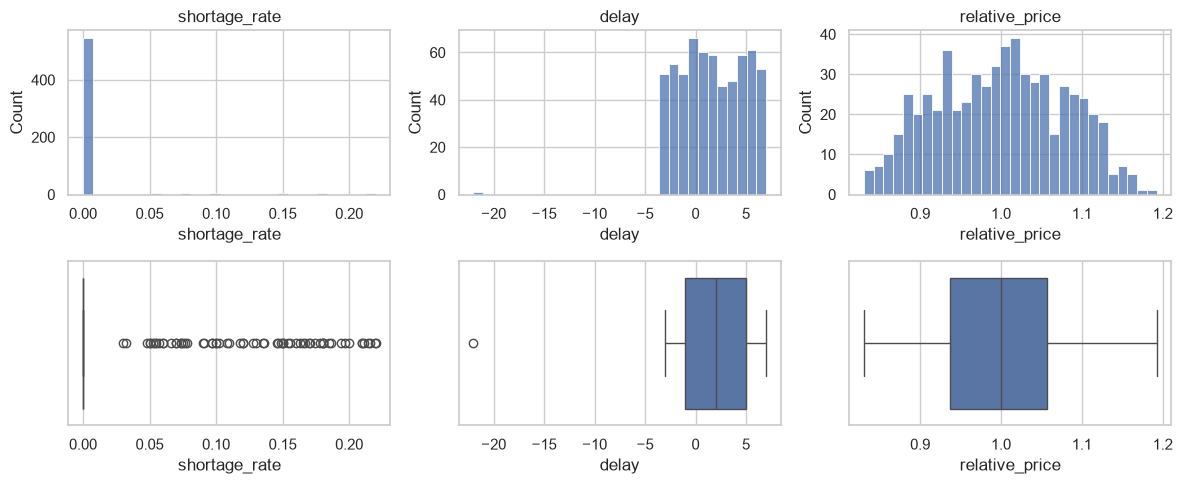

In [4]:
# Shortage rate: share of the ordered quantity that was not received
r["shortage_rate"] = (r["ordered_quantity"] - r["received_quantity"]) / r["ordered_quantity"]
# True if the row has a shortage
r["has_shortage"] = r["shortage_rate"] > 0
# Delay in days relative to the requested delivery date
r["delay"] = (r["receipt_date"] - r["requested_delivery_date"]).dt.days

# Relative price: price divided by the median price of the same item
item_median_price = r.groupby("item_code")["unit_price"].transform("median")
r["relative_price"] = r["unit_price"] / item_median_price

# Descriptive statistics of the 3 indicators
print(f"Rows with a shortage: {r['has_shortage'].sum()} / {len(r)} ({r['has_shortage'].mean():.1%})")
indicators = ["shortage_rate", "delay", "relative_price"]
display(r[indicators].describe().round(2))

# Histogram (top row) and boxplot (bottom row) for each indicator
fig, axes = plt.subplots(2, 3, figsize=(12, 5))
for j in range(3):
    col = indicators[j]
    sns.histplot(r[col], bins=30, ax=axes[0, j])
    sns.boxplot(x=r[col], ax=axes[1, j])
    axes[0, j].set_title(col)
plt.tight_layout()
plt.show()

- **Shortage rate:** zero for 9 rows out of 10, otherwise between 3% and 22%.
- **Delay:** small, from −22 to +7 days.
- **Relative price:** between 0.83 and 1.19, so no abnormal price.

Pearson correlations (linear relationships) and Spearman correlations (monotonic relationships), course 1:

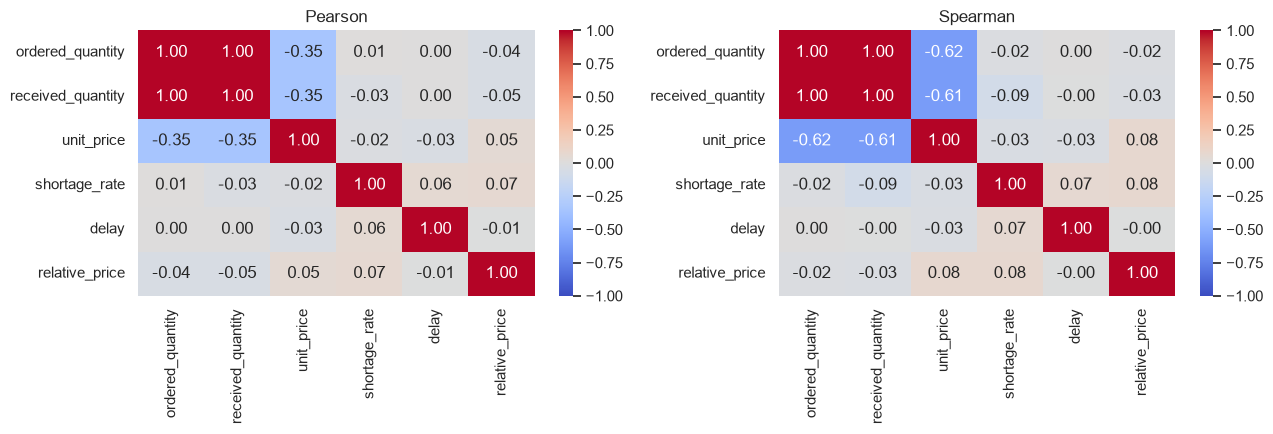

In [5]:
# Numeric variables to compare
variables = ["ordered_quantity", "received_quantity", "unit_price", "shortage_rate", "delay", "relative_price"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# Pearson correlation matrix (linear relationships)
sns.heatmap(r[variables].corr("pearson"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson")
# Spearman correlation matrix (monotonic relationships, based on ranks)
sns.heatmap(r[variables].corr("spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman")
plt.tight_layout()
plt.show()

Only the expected correlations stand out (ordered and received quantity, quantity and price). Shortage and delay are not related to anything.

### Anomaly detection

DBSCAN and Isolation Forest on the 4 indicators. The shortage rate, already between 0 and 1, is left unchanged; the others are min-max normalised. `eps` is read at the elbow of the k-distance curve.

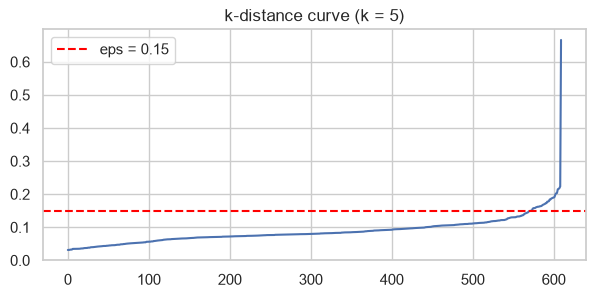

count  share_with_shortage
dbscan iforest                            
False  False      577                 0.06
       True        18                 1.00
True   False        2                 0.50
       True        13                 1.00

In [6]:
# Min-max normalisation: rescales a column between 0 and 1
def min_max(column):
    return (column - column.min()) / (column.max() - column.min())

# Table of the 4 variables used for anomaly detection
X = pd.DataFrame()
# The shortage rate is already between 0 and 1: we keep it as is
X["shortage_rate"] = r["shortage_rate"]
X["delay"] = min_max(r["delay"])
X["relative_price"] = min_max(r["relative_price"])
# log1p to reduce the effect of very large quantities
X["log_quantity"] = min_max(np.log1p(r["ordered_quantity"]))

# k-distance curve: distance from each point to its 5th neighbour, sorted
neighbors = NearestNeighbors(n_neighbors=5).fit(X)
distances, _ = neighbors.kneighbors(X)
k_distances = np.sort(distances[:, -1])

# Plot the curve and the eps value chosen at the elbow
plt.figure(figsize=(7, 3))
plt.plot(k_distances)
plt.axhline(0.15, color="red", ls="--", label="eps = 0.15")
plt.title("k-distance curve (k = 5)")
plt.legend()
plt.show()

# DBSCAN and Isolation Forest return -1 for anomalies
r["dbscan"] = DBSCAN(eps=0.15, min_samples=5).fit_predict(X) == -1
r["iforest"] = IsolationForest(contamination=0.05, random_state=42).fit_predict(X) == -1
# For each combination of the two methods: number of rows and share with a shortage
display(r.groupby(["dbscan", "iforest"])["has_shortage"].agg(count="size", share_with_shortage="mean").round(2))

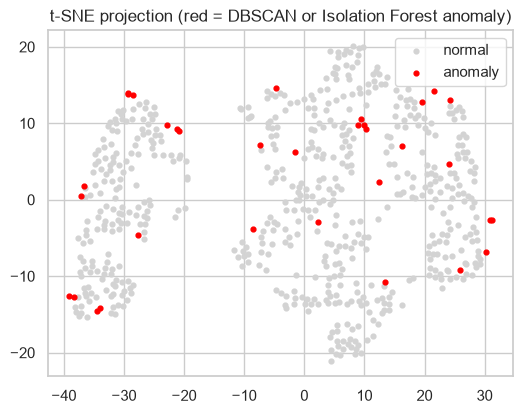

In [7]:
# t-SNE projection of the 4 variables in 2 dimensions to visualise the anomalies
tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)
# True if the row is an anomaly for at least one of the two methods
anomaly = r["dbscan"] | r["iforest"]

# Normal points in grey, anomalies in red
plt.figure(figsize=(6, 4.5))
plt.scatter(tsne[~anomaly, 0], tsne[~anomaly, 1], s=12, c="lightgrey", label="normal")
plt.scatter(tsne[anomaly, 0], tsne[anomaly, 1], s=12, c="red", label="anomaly")
plt.title("t-SNE projection (red = DBSCAN or Isolation Forest anomaly)")
plt.legend()
plt.show()

The anomalies are almost all rows with a shortage, scattered over the t-SNE: they do not form a group. Next question: **are the shortages concentrated in certain suppliers or sites?**

In [8]:
# "X ⇒ shortage" rules by supplier, by site and by category (the 3 largest lifts of each)
for col in ["supplier_partner_code", "ordering_facility_code", "item_category"]:
    print(rule_to_target(r, col, "has_shortage").head(3).round(3))
    print()

                        n  k  support  confidence   lift
supplier_partner_code                                   
BP-30079               10  3    0.005       0.300  2.815
BP-30033               11  3    0.005       0.273  2.559
BP-30037                8  2    0.003       0.250  2.346

                         n  k  support  confidence   lift
ordering_facility_code                                   
FCL-1014                15  4    0.007       0.267  2.503
FCL-1001                 8  2    0.003       0.250  2.346
FCL-1002                11  2    0.003       0.182  1.706

                        n  k  support  confidence   lift
item_category                                           
transport_service      30  6    0.010       0.200  1.877
communication_service  17  3    0.005       0.176  1.656
protective_equipment   47  7    0.011       0.149  1.398



**Conclusion:** the largest lifts (2.3 to 2.8 for suppliers and sites) rest on only 2 to 4 shortages, too few to speak of concentration; by category, the lifts stay below 1.9.

## 2. Stock balances

Expected equation: **closing = opening + received − outgoing − internal use − waste**. The `gap` is the difference between the declared closing and the expected closing; negative = stock disappeared.

In [9]:
# Sort by site, category and month to get the balances in order
s = stocks.sort_values(["facility_code", "item_category", "reporting_month"]).copy()

# Expected closing according to the stock equation
expected_closing = (s["opening_stock"] + s["received_quantity"] - s["outgoing_quantity"]
                    - s["documented_internal_use"] - s["documented_waste"])
# Gap = declared closing - expected closing (negative = stock disappeared)
s["gap"] = (s["closing_stock"] - expected_closing).round(2)

# A month's closing must equal the opening of the next month
next_opening = s.groupby(["facility_code", "item_category"])["opening_stock"].shift(-1)
breaks = (next_opening - s["closing_stock"]).abs() > 0.005
print("Breaks between two balances:", breaks.sum())
# Number of balances whose gap is zero (up to rounding)
print("Balances that satisfy the equation:", (s["gap"].abs() < 0.01).sum(), "/", len(s))
# Mean gap by balance status
s.groupby("inventory_status")["gap"].agg(["size", "mean"]).round(2)

Breaks between two balances: 0
Balances that satisfy the equation: 3 / 500


,size,mean
inventory_status,,
closed,444,0.37
provisional,38,-0.36
revised,18,-9.01


The balances chain correctly from one month to the next, but the equation is almost never satisfied. The `revised` balances have a mean gap of −9: spotted, but not corrected.

### Abnormal gaps

We use the **relative gap** (gap / available stock) to compare stocks of different sizes, with two rules: **IQR** and **modified z-score** (threshold −3.5).

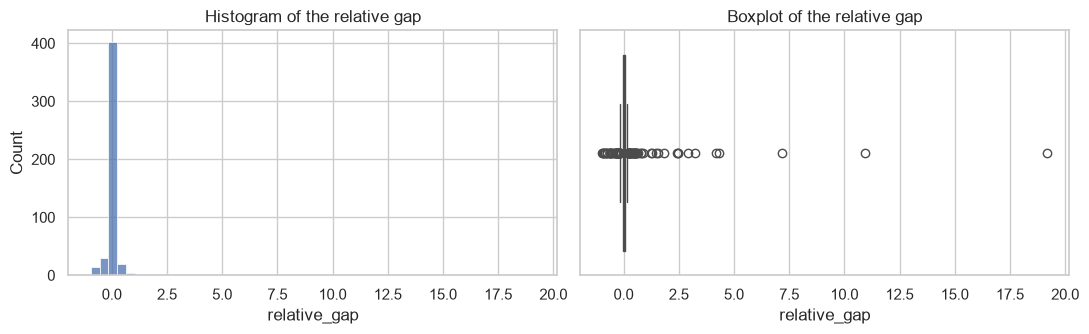

IQR threshold: -0.16 -> 40 flagged balances
modified z-score < -3.5: 35 balances


facility_code  item_category       
FCL-1027       biological_sample       8
FCL-1020       biological_sample       7
FCL-1019       biological_sample       7
FCL-1024       biological_sample       6
               protective_equipment    2
dtype: int64

In [10]:
# Stock available during the month = opening + received
s["available_stock"] = s["opening_stock"] + s["received_quantity"]
# No available stock: set NaN to avoid dividing by 0
s.loc[s["available_stock"] <= 0, "available_stock"] = np.nan
# Relative gap = gap divided by the available stock
s["relative_gap"] = s["gap"] / s["available_stock"]

# Histogram and boxplot of the relative gap
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(s["relative_gap"].dropna(), bins=50, ax=axes[0])
sns.boxplot(x=s["relative_gap"], ax=axes[1])
axes[0].set_title("Histogram of the relative gap")
axes[1].set_title("Boxplot of the relative gap")
plt.tight_layout()
plt.show()

# IQR rule: abnormal if the value is below Q1 - 1.5 x (Q3 - Q1)
q1 = s["relative_gap"].quantile(0.25)
q3 = s["relative_gap"].quantile(0.75)
iqr_threshold = q1 - 1.5 * (q3 - q1)
s["iqr"] = s["relative_gap"] < iqr_threshold

# Modified z-score: like a z-score, but with the median and the MAD (less sensitive to extremes)
median_value = s["relative_gap"].median()
mad = (s["relative_gap"] - median_value).abs().median()
s["modified_z"] = 0.6745 * (s["relative_gap"] - median_value) / mad

print(f"IQR threshold: {iqr_threshold:.2f} -> {s['iqr'].sum()} flagged balances")
print(f"modified z-score < -3.5: {(s['modified_z'] < -3.5).sum()} balances")
# The site + category pairs with the most balances flagged by the IQR rule
s[s["iqr"]].groupby(["facility_code", "item_category"]).size().sort_values(ascending=False).head(5)

The flagged balances mostly concern **biological samples**, at FCL-1027, FCL-1020, FCL-1019 and FCL-1024. We also look at the losses in absolute value:

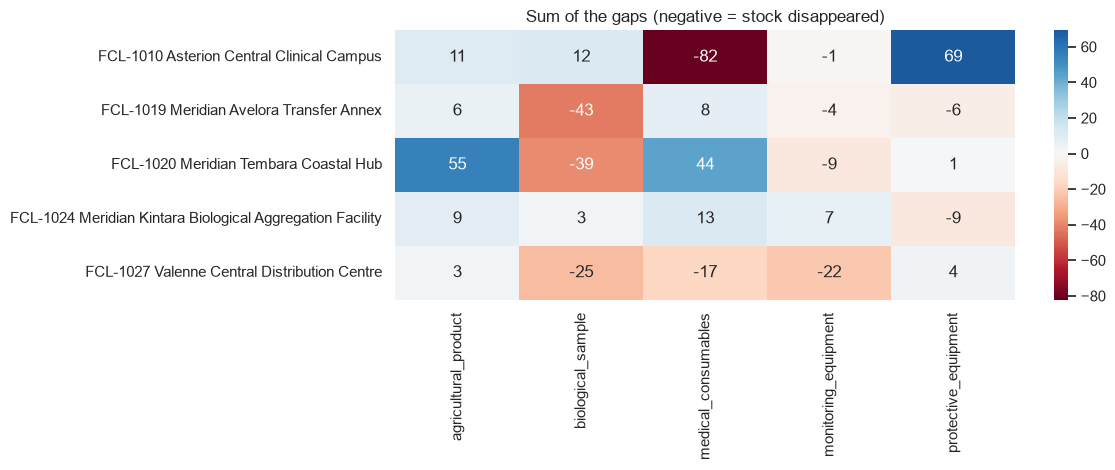

,,gap_sum,mean_stock,flagged_balances
facility_code,item_category,,,
FCL-1010,medical_consumables,-82.2,159.8,1
FCL-1019,biological_sample,-42.6,16.8,7
FCL-1020,biological_sample,-38.7,7.0,7
FCL-1027,biological_sample,-25.2,7.1,8


In [11]:
# Readable site name (code + name) for the heatmap
s["site"] = s["facility_code"] + " " + s["facility_code"].map(sites["facility_name"])
# Sum of the gaps for each site (rows) and each category (columns)
gap_sum = s.pivot_table(index="site", columns="item_category", values="gap", aggfunc="sum")

# Heatmap: red = stock disappeared, blue = excess stock
plt.figure(figsize=(10, 3.5))
sns.heatmap(gap_sum, annot=True, fmt=".0f", cmap="RdBu", center=0)
plt.title("Sum of the gaps (negative = stock disappeared)")
plt.xlabel("")
plt.ylabel("")
plt.show()

# For each site + category pair: total loss, mean stock and number of flagged balances
per_pair = s.groupby(["facility_code", "item_category"]).agg(gap_sum=("gap", "sum"),
                                                              mean_stock=("opening_stock", "mean"),
                                                              flagged_balances=("iqr", "sum"))
# The 4 pairs that lose the most
per_pair.sort_values("gap_sum").head(4).round(1)

- **FCL-1010, medical consumables:** largest loss (−82 cases), but moderate for a mean stock of 160.
- **FCL-1019 and FCL-1020, biological samples:** −43 and −39 lots, i.e. several times their mean stock.

### The "pure transit" months

In the flagged balances of these two sites, in some months the received quantity is **exactly equal** to the outgoing quantity.

In [12]:
# Transit months: something was received and everything went back out (received = outgoing)
s["transit"] = (s["received_quantity"] > 0) & (s["received_quantity"] == s["outgoing_quantity"])
transit = s[s["transit"]]
display(transit[["facility_code", "item_category", "reporting_month", "opening_stock",
                 "received_quantity", "closing_stock", "gap", "iqr"]])

# Mean gap of the transit months compared with the other months
print("Mean gap:", s.groupby("transit")["gap"].mean().round(2).to_dict())
# Cross table: transit months x flagged by the IQR rule
pd.crosstab(s["transit"], s["iqr"], rownames=["transit month"], colnames=["flagged by the IQR rule"], margins=True)

,facility_code,item_category,reporting_month,opening_stock,received_quantity,closing_stock,gap,iqr
102,FCL-1019,biological_sample,2018-05-01,57.30,3.0,30.32,-17.63,True
106,FCL-1019,biological_sample,2019-11-01,28.43,7.0,3.38,-21.80,True
108,FCL-1019,biological_sample,2020-06-01,9.52,5.0,0.00,-8.83,True
110,FCL-1019,biological_sample,2021-05-01,5.53,2.0,0.00,-4.49,True
114,FCL-1019,biological_sample,2023-11-01,6.57,8.0,0.00,-5.72,True
116,FCL-1019,biological_sample,2024-05-01,0.00,3.0,0.00,0.31,False
119,FCL-1019,biological_sample,2025-06-01,2.72,8.0,0.00,-2.50,True
200,FCL-1020,biological_sample,2018-02-01,37.80,3.0,21.66,-12.30,True
204,FCL-1020,biological_sample,2019-08-01,6.37,2.0,0.00,-4.97,True
211,FCL-1020,biological_sample,2022-02-01,8.63,7.0,0.00,-8.15,True


Mean gap: {False: 0.18, True: -8.95}


flagged by the IQR rule,False,True,All
transit month,,,
False,459,30,489
True,1,10,11
All,460,40,500


**11 transit months**, all on the samples of FCL-1019 and FCL-1020. Mean gap of −9 (versus +0.2 elsewhere) and closing at 0 in 8 cases: the lot comes in, goes out, and the stock already there disappears. **The IQR rule flags 10 out of 11** (versus 30 out of 489 for the other months); the only miss had an already empty stock.

### Comparison with multivariate methods

Isolation Forest and LOF on the balance ratios, without standardisation because these are ratios and a binary indicator.

In [13]:
# Balance variables divided by the available stock (ratios) + zero-closing indicator
Xs = pd.DataFrame()
Xs["gap"] = s["relative_gap"]
Xs["outgoing"] = s["outgoing_quantity"] / s["available_stock"]
Xs["usage"] = (s["documented_internal_use"] + s["documented_waste"]) / s["available_stock"]
Xs["zero_closing"] = (s["closing_stock"] == 0).astype(int)
# Balances without available stock give NaN: we replace them with 0
Xs = Xs.fillna(0)

# The 4 methods to compare (True = balance flagged as abnormal)
methods = {
    "IQR on the relative gap (univariate)": s["iqr"],
    "Modified z-score (univariate)": s["modified_z"] < -3.5,
    "Isolation Forest (multivariate)": IsolationForest(contamination=0.05, random_state=42).fit_predict(Xs) == -1,
    "LOF (multivariate)": LocalOutlierFactor(n_neighbors=20, contamination=0.05).fit_predict(Xs) == -1,
}

# For each method: number of flagged balances and how many are transit months
comparison = []
for name, flagged in methods.items():
    comparison.append({"method": name,
                        "flagged balances": flagged.sum(),
                        "of which transit months (out of 11)": (flagged & s["transit"]).sum()})
pd.DataFrame(comparison)

,method,flagged balances,of which transit months (out of 11)
0,IQR on the relative gap (univariate),40,10
1,Modified z-score (univariate),35,10
2,Isolation Forest (multivariate),25,0
3,LOF (multivariate),25,1


Isolation Forest and LOF miss the transit months: they detect extreme values, whereas these months have normal values taken one by one. It is the business rule (the equation) that makes them abnormal: an outlier is not necessarily an anomaly, and vice versa.

## 3. Shipments: the circuit of biological samples

In [14]:
# Returns the most frequent value of a column
def most_frequent(column):
    return column.mode()[0]

# Keep only the shipments of biological samples
bio = shipments[shipments["item_category"] == "biological_sample"].copy()
# Route = origin site → destination site
bio["route"] = bio["origin_facility_code"] + " → " + bio["destination_facility_code"]

# For each route: number of shipments and most frequent actors
routes = bio.groupby("route").agg(n=("shipment_number", "size"),
                                            purpose=("declared_purpose", most_frequent),
                                            sender=("sender_partner_code", most_frequent),
                                            receiver=("receiver_partner_code", most_frequent),
                                            carrier=("carrier_partner_code", most_frequent))
# The 5 most used routes
routes.sort_values("n", ascending=False).head(5)

,n,purpose,sender,receiver,carrier
route,,,,,
FCL-1011 → FCL-1007,8,temperature-controlled clinical programme delivery,BP-30078,BP-30021,BP-30047
FCL-1019 → FCL-1019,7,environmental and wildlife reference materials,BP-30056,BP-30078,BP-30047
FCL-1030 → FCL-1024,7,environmental and wildlife reference materials,BP-30056,BP-30078,BP-30047
FCL-1011 → FCL-1010,7,temperature-controlled clinical programme delivery,BP-30078,BP-30021,BP-30047
FCL-1020 → FCL-1020,4,environmental and wildlife reference materials,BP-30056,BP-30078,BP-30047


In [15]:
# Information on the sites of the circuit
display(sites.loc[["FCL-1030", "FCL-1024", "FCL-1019", "FCL-1020", "FCL-1011", "FCL-1007", "FCL-1010"],
                  ["facility_name", "facility_category", "storage_capabilities"]])
# Information on the partners of the circuit (including the risk level)
partners.loc[["BP-30056", "BP-30078", "BP-30021", "BP-30047"], ["partner_name", "partner_role", "risk_class"]]

,facility_name,facility_category,storage_capabilities
facility_code,,,
FCL-1030,Kintara Cave Authority Field Depot,field_depot,ambient
FCL-1024,Meridian Kintara Biological Aggregation Facility,warehouse,ambient;secure_cage;2-8C;frozen
FCL-1019,Meridian Avelora Transfer Annex,transfer_hub,ambient;secure_cage;2-8C;frozen
FCL-1020,Meridian Tembara Coastal Hub,transfer_hub,ambient;secure_cage;2-8C;frozen
FCL-1011,Meridian Valenne Headquarters,office,ambient
FCL-1007,Asterion Avelora Executive Clinic,clinical_delivery_point,2-8C;controlled_access
FCL-1010,Asterion Central Clinical Campus,laboratory_delivery_point,2-8C;controlled_access


,partner_name,partner_role,risk_class
partner_code,,,
BP-30056,Horizon Field Research Cooperative,customer,standard
BP-30078,Meridian BioLogistics,carrier,standard
BP-30021,Asterion Clinical Institute,customer,review
BP-30047,Northstar Cold Chain Services,carrier,elevated


Three main routes, always with the carrier **Northstar (BP-30047), rated "elevated" risk**:
1. **FCL-1030 → FCL-1024**: Kintara caves depot → Meridian, purpose "wildlife material";
2. **FCL-1019 → FCL-1019 and FCL-1020 → FCL-1020**: sites that send parcels **to themselves**;
3. **FCL-1011 → FCL-1007 and FCL-1010**: Meridian headquarters (office without a fridge) → Asterion clinics, purpose "clinical programme".

### Shipments to itself and transit months

In [16]:
# Shipments whose origin site is also the destination site
to_self = bio[bio["origin_facility_code"] == bio["destination_facility_code"]].copy()
# Month of the shipment (1st day of the month), to compare it with the balance month
to_self["month"] = to_self["dispatch_time"].dt.to_period("M").dt.to_timestamp()

# Match each shipment to itself with the transit month of the same site and the same month
matched = to_self.merge(transit, left_on=["origin_facility_code", "month"],
                        right_on=["facility_code", "reporting_month"])
display(matched[["shipment_number", "origin_facility_code", "month", "declared_quantity", "received_quantity", "gap"]])
# How many have exactly the same quantity in both tables
print("Same quantity:", (matched["declared_quantity"] == matched["received_quantity"]).sum(), "/", len(to_self))

,shipment_number,origin_facility_code,month,declared_quantity,received_quantity,gap
0,SHP-2018-00004,FCL-1020,2018-02-01,3,3.0,-12.30
1,SHP-2018-00032,FCL-1019,2018-05-01,3,3.0,-17.63
2,SHP-2019-00009,FCL-1020,2019-08-01,2,2.0,-4.97
3,SHP-2019-00041,FCL-1019,2019-11-01,7,7.0,-21.80
4,SHP-2020-00038,FCL-1019,2020-06-01,5,5.0,-8.83
5,SHP-2021-00028,FCL-1019,2021-05-01,2,2.0,-4.49
6,SHP-2022-00018,FCL-1020,2022-02-01,7,7.0,-8.15
7,SHP-2023-00071,FCL-1019,2023-11-01,8,8.0,-5.72
8,SHP-2024-00011,FCL-1019,2024-05-01,3,3.0,0.31
9,SHP-2024-00044,FCL-1020,2024-08-01,3,3.0,-12.36


Same quantity: 11 / 11


The 11 shipments to itself match the 11 transit months (same site, same month, same quantity): **these are fake shipments that hide the disappearance**.

### Shipment graph

Each site is a node, each route a link weighted by quantity. For each site: in-strength and out-strength, balance (outgoing − incoming) and betweenness.

In [17]:
# Total quantity shipped for each (origin, destination) pair
links = bio.groupby(["origin_facility_code", "destination_facility_code"])["declared_quantity"].sum().reset_index()

# Build the directed graph: one link per route, weighted by quantity
G = nx.DiGraph()
for _, link in links.iterrows():
    G.add_edge(link["origin_facility_code"], link["destination_facility_code"], weight=link["declared_quantity"])

# Loops = links from a site to itself
loops = [u for u, v in nx.selfloop_edges(G)]
print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} links, density {nx.density(G):.3f}, loops: {loops}")

# For each site: quantity received, quantity sent and bridge role (betweenness)
nodes = pd.DataFrame({"in_strength": dict(G.in_degree(weight="weight")),
                       "out_strength": dict(G.out_degree(weight="weight")),
                       "betweenness": nx.betweenness_centrality(G)})
# Balance: positive = the site sends more than it receives (source), negative = sink
nodes["balance"] = nodes["out_strength"] - nodes["in_strength"]
nodes["site"] = nodes.index.map(sites["facility_name"])
nodes = nodes.sort_values("balance", ascending=False).round(3)

print("Sites that send the most (sources):")
display(nodes.head(3))
print("Sites that receive the most (sinks):")
display(nodes.tail(2))

21 nodes, 21 links, density 0.050, loops: ['FCL-1019', 'FCL-1020']
Sites that send the most (sources):


,in_strength,out_strength,betweenness,balance,site
FCL-1011,15,118,0.026,103,Meridian Valenne Headquarters
FCL-1030,15,33,0.005,18,Kintara Cave Authority Field Depot
FCL-1020,15,33,0.000,18,Meridian Tembara Coastal Hub


Sites that receive the most (sinks):


,in_strength,out_strength,betweenness,balance,site
FCL-1010,65,18,0.016,-47,Asterion Central Clinical Campus
FCL-1007,55,0,0.000,-55,Asterion Avelora Executive Clinic


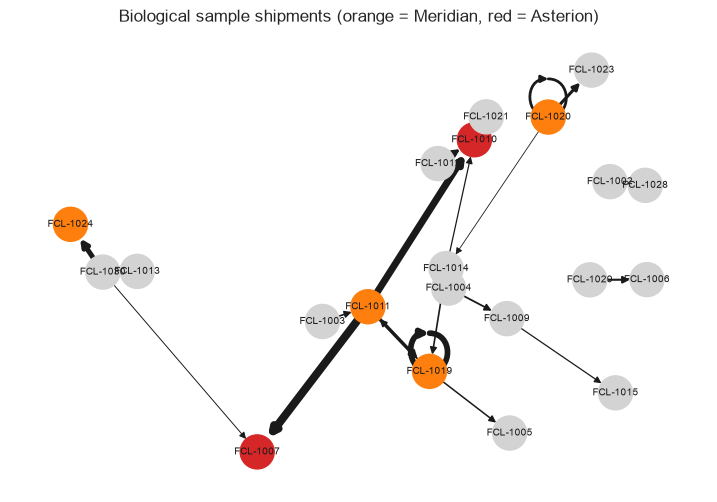

Louvain: 7 communities, modularity 0.60
['FCL-1003', 'FCL-1007', 'FCL-1010', 'FCL-1011', 'FCL-1012', 'FCL-1021']
['FCL-1004', 'FCL-1009', 'FCL-1015']
['FCL-1005', 'FCL-1014', 'FCL-1019']
['FCL-1013', 'FCL-1024', 'FCL-1030']


In [18]:
# Colour of each node according to the company operating the site
colors = []
for site in G.nodes:
    operator = sites.loc[site, "operating_partner_code"]
    if operator == "BP-30078":
        colors.append("tab:orange")  # Meridian
    elif operator == "BP-30021":
        colors.append("tab:red")     # Asterion
    else:
        colors.append("lightgrey")

# Arrow thickness proportional to the quantity shipped
widths = [0.5 + G[u][v]["weight"] / 10 for u, v in G.edges]

# Draw the graph (fixed seed to always get the same layout)
plt.figure(figsize=(9, 6))
position = nx.spring_layout(G, seed=42, k=0.6)
nx.draw_networkx(G, position, node_color=colors, node_size=600, font_size=7, width=widths, arrows=True)
plt.title("Biological sample shipments (orange = Meridian, red = Asterion)")
plt.axis("off")
plt.show()

# Louvain: community detection on the undirected graph, without loops
U = G.to_undirected()
U.remove_edges_from(list(nx.selfloop_edges(U)))
communities = nx.community.louvain_communities(U, weight="weight", seed=42)
# Modularity: quality of the partition (close to 1 = well-separated communities)
modularity = nx.community.modularity(U, communities, weight="weight")
print(f"Louvain: {len(communities)} communities, modularity {modularity:.2f}")
# Display the 4 largest communities
for c in sorted(communities, key=len, reverse=True)[:4]:
    print(sorted(c))

- **FCL-1011 (Meridian headquarters) is a source:** 118 lots sent for 15 received.
- **FCL-1010 and FCL-1007 (Asterion clinics) are sinks.**
- **The loops** on FCL-1019 and FCL-1020 are the fake shipments.

Louvain separates the Kintara part (FCL-1030, FCL-1024) from the headquarters + clinics group. **FCL-1024 ships nothing**: no passage is recorded between these two groups.

### Co-occurrences and association rules

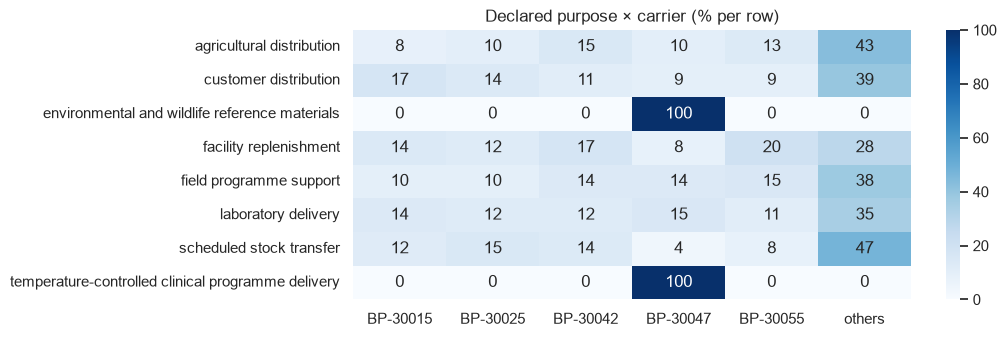

In [19]:
# Keep the 5 most used carriers, the others are grouped under "others"
top5 = shipments["carrier_partner_code"].value_counts().index[:5]
carrier = shipments["carrier_partner_code"].copy()
carrier[~carrier.isin(top5)] = "others"

# Co-occurrence matrix purpose x carrier, in % of each row
cooccurrence = pd.crosstab(shipments["declared_purpose"], carrier, normalize="index") * 100

plt.figure(figsize=(9, 3.5))
sns.heatmap(cooccurrence, annot=True, fmt=".0f", cmap="Blues")
plt.title("Declared purpose × carrier (% per row)")
plt.xlabel("")
plt.ylabel("")
plt.show()

Both purposes go **100% through BP-30047**. Apriori on all shipments (support ≥ 2%, confidence ≥ 0.8, lift ≥ 3):

In [20]:
# Columns describing a shipment
columns = ["item_category", "declared_purpose", "carrier_partner_code", "sender_partner_code",
            "receiver_partner_code", "origin_facility_code", "destination_facility_code"]
# One true/false column per value (format expected by Apriori)
items = pd.get_dummies(shipments[columns], prefix_sep="=").astype(bool)

# Frequent itemsets (present in at least 2% of the shipments), then rules with lift >= 3
frequent = apriori(items, min_support=0.02, use_colnames=True, max_len=4)
rules = association_rules(frequent, metric="lift", min_threshold=3)

# Keep the reliable rules (confidence >= 0.8) that start from a single item
rules = rules[(rules["confidence"] >= 0.8) & (rules["antecedents"].apply(len) == 1)].copy()
# Number of shipments covered by the rule
rules["n"] = (rules["support"] * len(shipments)).round().astype(int)
# Premise and conclusion as readable text
rules["premise"] = rules["antecedents"].apply(lambda x: ", ".join(x))
rules["conclusion"] = rules["consequents"].apply(lambda x: ", ".join(sorted(x)))

# For each declared purpose, display the rule with the longest conclusion
purposes = rules[rules["premise"].str.startswith("declared_purpose")]
longest = purposes.groupby("premise")["conclusion"].apply(lambda x: x.str.len().idxmax())
purposes.loc[longest, ["premise", "conclusion", "n", "confidence", "lift"]].round(2)

,premise,conclusion,n,confidence,lift
560,declared_purpose=environmental and wildlife reference materials,"carrier_partner_code=BP-30047, item_category=biological_sample, receiver_partner_code=BP-30078",18,1.0,23.68
1136,declared_purpose=temperature-controlled clinical programme delivery,"carrier_partner_code=BP-30047, origin_facility_code=FCL-1011, receiver_partner_code=BP-30021",26,1.0,16.67


Without any starting hypothesis, Apriori finds the two circuits with a **confidence of 1** (18 "wildlife" shipments, 26 "clinical programme").

In [21]:
# First "wildlife" shipment and first delivery to the clinics
shp = pd.read_csv("../data/logistics/clean/shipments_clean.csv", parse_dates=["dispatch_time"])
wildlife = shp[shp["declared_purpose"] == "environmental and wildlife reference materials"]
clinic = shp[shp["declared_purpose"] == "temperature-controlled clinical programme delivery"]
print("First \"wildlife\" shipment:", wildlife["dispatch_time"].min().date(), "| first delivery to the clinics:", clinic["dispatch_time"].min().date())

First "wildlife" shipment: 2018-02-16 | first delivery to the clinics: 2014-07-10


## 4. Stock adjustments

Negative = stock withdrawal, positive = addition.

In [22]:
# True if the adjustment removes stock
adjustments["negative"] = adjustments["adjustment_quantity"] < 0
# For each adjustment reason: count, total quantity and share of withdrawals
adjustment_reasons = adjustments.groupby("adjustment_reason").agg(count=("adjustment_quantity", "size"),
                                                            total=("adjustment_quantity", "sum"),
                                                            negative_share=("negative", "mean"))
# Sorted from the reason that removes the most to the one that adds the most
adjustment_reasons.sort_values("total").round(2)

,count,total,negative_share
adjustment_reason,,,
specialist programme issue,11,-23.65,1.00
transfer posting correction,24,-22.47,0.67
procedure stock issue,10,-22.41,1.00
controlled-area consumption,9,-16.84,1.00
cycle count reconciliation,5,-16.22,1.00
unit-of-measure review,12,-8.80,0.67
cycle count correction,23,-7.69,0.48
quality-hold release,21,-1.56,0.52
damaged packaging write-off,16,-1.19,0.44


In [23]:
# Separate the two Asterion clinics from the other sites
adjustments["group"] = np.where(adjustments["facility_code"].isin(["FCL-1007", "FCL-1010"]),
                                 "Asterion clinics", "other sites")

# Sites where adjustments are approved by this particular role
special_role = adjustments["approved_by_role"] == "specialist programme administrator"
print("Sites where the \"specialist programme administrator\" approves:",
      sorted(adjustments.loc[special_role, "facility_code"].unique()))
# How many of the Asterion-specific withdrawals are approved by this role
# (then: number of adjustments per reason, in the Asterion clinics and elsewhere)
asterion_reasons = ["controlled-area consumption", "procedure stock issue", "specialist programme issue"]
asterion_specific = adjustments["adjustment_reason"].isin(asterion_reasons)
print("Asterion-specific withdrawals:", asterion_specific.sum(), "| approved by this role:", (asterion_specific & special_role).sum())
pd.crosstab(adjustments["adjustment_reason"], adjustments["group"])

Sites where the "specialist programme administrator" approves: ['FCL-1007', 'FCL-1010']
Asterion-specific withdrawals: 30 | approved by this role: 13


group,Asterion clinics,other sites
adjustment_reason,,
controlled-area consumption,9,0
cycle count correction,0,23
cycle count reconciliation,0,5
damaged packaging write-off,2,14
late receipt posting,3,6
procedure stock issue,10,0
quality-hold release,0,21
specialist programme issue,11,0
transfer posting correction,0,24


Three withdrawal reasons exist **only in the Asterion clinics** (30 withdrawals). 13 of them are approved by a "specialist programme administrator", a role absent from the other sites.

### Adjustments linked to the "wildlife" shipments

In [24]:
# Adjustments that cite a shipment, joined with the information of that shipment
linked = adjustments.dropna(subset=["related_shipment_number"])
linked = linked.merge(shipments, left_on="related_shipment_number", right_on="shipment_number", suffixes=("", "_exp"))
# Number of days between the shipment and the adjustment
linked["days"] = (linked["adjustment_date"] - linked["dispatch_time"]).dt.days

# A link is consistent if: same category, 0 to 31 days after dispatch, and origin or destination site
same_category = linked["item_category"] == linked["item_category_exp"]
delay_ok = linked["days"].between(0, 31)
same_site = (linked["facility_code"] == linked["origin_facility_code"]) | (linked["facility_code"] == linked["destination_facility_code"])
consistent = linked[same_category & delay_ok & same_site]
display(consistent[["adjustment_number", "facility_code", "adjustment_quantity", "adjustment_reason", "declared_purpose", "days"]])

# How many "wildlife" shipments are followed by a consistent withdrawal
wildlife = shipments[shipments["declared_purpose"] == "environmental and wildlife reference materials"]
followed_by_withdrawal = wildlife["shipment_number"].isin(consistent["shipment_number"])
print(f"\"Wildlife\" shipments followed by a withdrawal: {followed_by_withdrawal.sum()} / {len(wildlife)}")
# "Wildlife" shipments without a withdrawal
wildlife.loc[~followed_by_withdrawal, ["shipment_number", "origin_facility_code", "dispatch_time"]]

,adjustment_number,facility_code,adjustment_quantity,adjustment_reason,declared_purpose,days
4,ADJ-2018-00019,FCL-1020,-2.01,cycle count reconciliation,environmental and wildlife reference materials,11
5,ADJ-2018-00023,FCL-1024,-4.14,transfer posting correction,environmental and wildlife reference materials,7
6,ADJ-2018-00027,FCL-1019,-2.95,transfer posting correction,environmental and wildlife reference materials,5
7,ADJ-2019-00039,FCL-1020,-2.69,transfer posting correction,environmental and wildlife reference materials,21
11,ADJ-2019-00046,FCL-1024,-1.08,quality-hold release,environmental and wildlife reference materials,16
12,ADJ-2019-00052,FCL-1019,-4.81,transfer posting correction,environmental and wildlife reference materials,21
14,ADJ-2020-00061,FCL-1024,-3.84,cycle count reconciliation,environmental and wildlife reference materials,19
15,ADJ-2020-00065,FCL-1019,-3.59,cycle count reconciliation,environmental and wildlife reference materials,17
16,ADJ-2021-00071,FCL-1024,-3.39,cycle count reconciliation,environmental and wildlife reference materials,4
21,ADJ-2021-00078,FCL-1019,-1.25,quality-hold release,environmental and wildlife reference materials,9


"Wildlife" shipments followed by a withdrawal: 17 / 18


,shipment_number,origin_facility_code,dispatch_time
379,SHP-2024-00011,FCL-1019,2024-05-31 09:00:00


The 17 consistent links are **all withdrawals** of samples at Meridian, 4 to 21 days after a "wildlife" shipment, with a mundane reason. The only exception (SHP-2024-00011) is the month when the stock was already empty: nothing to hide.

## Conclusion

The orders show nothing suspicious: shortages are concentrated in no supplier or site. The problem lies in Meridian's **biological samples**:

1. **They disappear from the stocks** of FCL-1019 and FCL-1020 in the "transit" months (11 months, about 9 lots lost each time).
2. **These disappearances are hidden** by fake shipments to itself (11 out of 11), then erased from the accounts by "correction" withdrawals (17 "wildlife" shipments out of 18).
3. **Two flows go through Meridian**, always with the at-risk carrier Northstar:
   - the "wildlife" shipments arrive at the Meridian warehouses (from the Kintara caves depot, or through the fake shipments to itself) and disappear there;
   - the Meridian headquarters sends the Asterion clinics lots that it never received, and they leave the stock there with reasons seen nowhere else.

Nothing links the two flows in the data: almost no lot goes from the warehouses to the headquarters, and the deliveries to the clinics start in 2014, four years before the first "wildlife" shipment. Logistics does not say what the lots contain or what they are used for: it is up to the other datasets (ecology, health, public records) to confirm it.